# pix2pix

This notebook demonstrate pix2pix using PyTorch with the facades dataset. It involves dataset download, loading, model definition, and training loop setup.
This code downloads and extracts the facades dataset from the original pix2pix website.
-The Facades images are assumed to be “paired”: each image is split in half horizontally—with the left half being the input (e.g. a segmentation map) and the right half the target (e.g. the facade).
- For a real project you may need to adjust hyperparameters and extend the model architectures.

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import torchvision.transforms.v2 as T

from PIL import Image
from tqdm.notebook import tqdm
from torchsummary import summary
from torch.utils.data import Dataset, DataLoader

# Check if CUDA is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [2]:
class Pix2PixDataset(Dataset):
    def __init__(self, root_dir, mode="train", transform=None, target='right'):
        """
        Args:
            root_dir (string): Directory with all the images. Expected folder structure:
                               facades/train and facades/test.
            mode (string): "train" or "test"
            transform (callable, optional): Optional transform to be applied on a sample.
        """
        self.root_dir = os.path.join(root_dir, mode)
        self.image_files = sorted(os.listdir(self.root_dir))
        self.transform = transform
        self.target = target

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.image_files[idx])
        img = Image.open(img_path).convert("RGB")
        w, h = img.size
        # Split image into two halves: left is input, right is target.
        w2 = int(w / 2)

        if self.target == 'right':
            input_img = img.crop((0, 0, w2, h))
            target_img = img.crop((w2, 0, w, h))
        else:
            input_img = img.crop((w2, 0, w, h))
            target_img = img.crop((0, 0, w2, h))
        
        if self.transform:
            input_img = self.transform(input_img)
            target_img = self.transform(target_img)

        return {"input": input_img, "target": target_img}

In [3]:
# Define transforms: resize and convert to tensor (normalize to [-1, 1])
transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Resize((256, 256)),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

datasets_root = "/pgeoprj2/ciag2024/dados/pix2pix/facades/"
dataset = Pix2PixDataset(root_dir=datasets_root, mode="train", transform=transform, target='left')

# Create a DataLoader for the dataset
dataloader = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=2)

# Generator: A Simplified U-Net Style Architecture

The generator is designed as an encoder-decoder network with skip connections. In U-Net style architectures, features from the encoder (downsampling path) are “skipped” to the corresponding decoder (upsampling path) layers. This helps preserve spatial details and leads to sharper outputs.

1. Encoder (Downsampling Path)
The encoder consists of several “down” blocks that progressively reduce the spatial dimensions (height and width) while increasing the number of feature channels. In this code, the encoder is built with four downsampling blocks.



In [4]:
# Generator: a simplified U-Net style architecture
class Generator(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, features=64):
        super(Generator, self).__init__()
        # Encoder
        self.down1 = self._block(in_channels, features, normalize=False)  # 256 -> 128
        self.down2 = self._block(features, features*2)                     # 128 -> 64
        self.down3 = self._block(features*2, features*4)                   # 64 -> 32
        self.down4 = self._block(features*4, features*8)                   # 32 -> 16
        # Each block uses a convolution with stride 2 to downsample the image.
        # Batch normalization (except for the first block) and a LeakyReLU
        # activation are applied.

        # Bottleneck
        # Aim: to have abstract representation of the image at the lowest resolution.
        # # It reduces further: 16x16 -> 8x8
        self.bottleneck = nn.Sequential(
            nn.Conv2d(features*8, features*8, kernel_size=4, stride=2, padding=1),
            nn.ReLU()
        )  # 16 -> 8

        # Decoder
        # The purpose is to reconstruct the image back to its original resolution
        # while using the high-level features captured by the botleneck
        self.up1 = self._up_block(features*8, features*8)  # 8 -> 16
        self.up2 = self._up_block(features*16, features*4) # 16 -> 32 (skip connection doubles channels)
        self.up3 = self._up_block(features*8, features*2)  # 32 -> 64
        self.up4 = self._up_block(features*4, features)    # 64 -> 128

        self.final_up = nn.Sequential(
            nn.ConvTranspose2d(features*2, out_channels, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )  # 128 -> 256
        # Each up block uses a transposed convolution to upsample the feature
        # map, followed by batch normalization and a ReLU activation.

    def _block(self, in_channels, out_channels, normalize=True):
        layers = [nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1)]
        if normalize:
            layers.append(nn.BatchNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2))
        return nn.Sequential(*layers)

    def _up_block(self, in_channels, out_channels):
        # ConvTranspose2d block with BatchNorm and ReLU
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        ]
        return nn.Sequential(*layers)

    def forward(self, x):
        # Encoding
        d1 = self.down1(x)  # Output of first encoder block
        d2 = self.down2(d1) # Output of second encoder block
        d3 = self.down3(d2) # Output of third encoder block
        d4 = self.down4(d3) # Output of fourth encoder block
        bottleneck = self.bottleneck(d4)
        #  Decoding with skip connections
        up1 = self.up1(bottleneck)  # Upsample bottleneck output
        up2 = self.up2(torch.cat([up1, d4], dim=1))  # Skip: concat with d4
        up3 = self.up3(torch.cat([up2, d3], dim=1))  # Skip: concat with d3
        up4 = self.up4(torch.cat([up3, d2], dim=1))  # Skip: concat with d2
        out = self.final_up(torch.cat([up4, d1], dim=1)) # Skip: concat with d1
        # At each decoder step, the output from the corresponding encoder layer
        # (for example, d4 with up1, d3 with up2, etc.) is concatenated along
        # the channel dimension.
        return out


In [5]:
gen = Generator().to(device)
summary(gen, (3, 256, 256))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 128, 128]           3,136
         LeakyReLU-2         [-1, 64, 128, 128]               0
            Conv2d-3          [-1, 128, 64, 64]         131,200
       BatchNorm2d-4          [-1, 128, 64, 64]             256
         LeakyReLU-5          [-1, 128, 64, 64]               0
            Conv2d-6          [-1, 256, 32, 32]         524,544
       BatchNorm2d-7          [-1, 256, 32, 32]             512
         LeakyReLU-8          [-1, 256, 32, 32]               0
            Conv2d-9          [-1, 512, 16, 16]       2,097,664
      BatchNorm2d-10          [-1, 512, 16, 16]           1,024
        LeakyReLU-11          [-1, 512, 16, 16]               0
           Conv2d-12            [-1, 512, 8, 8]       4,194,816
             ReLU-13            [-1, 512, 8, 8]               0
  ConvTranspose2d-14          [-1, 512,

# Discriminator: PatchGAN Classifier

The discriminator is designed to classify whether local patches in an image are real or fake rather than classifying the entire image as a whole. This “PatchGAN” approach focuses on high-frequency structure.

Remember that the calculation of the output dimensions after a convolution layer with stride and padding is equal to:

$$ W_{out} = \frac{W_{in} + 2*\text{pad} - \text{Kernel size}}{\text{stride}} + 1
$$
where $W_{in}$ is the input dimension (height or width).



In [6]:
# Discriminator: PatchGAN classifier
# The Discriminator class inherits from torch.nn.Module, which is the standard
# way of defining a neural network module in PyTorch.
class Discriminator(nn.Module):
    def __init__(self, in_channels=6, features=64):
        # in_channels = input + target images concatenated along channel dimension.
        # Typically, RGB images (3 channels each): concatenation gives 6 channels
        # features=64 sets the number of filters for the first convolutional layer.
        # Subsequent layers multiply this number.
        # For facade, input to discriminator is [batch_size, 6, 256, 256]
        super(Discriminator, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, features, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),
            # Takes the 6-channel concatenated input and applies a 4×4 convolution.
            # With a stride of 2 and padding of 1, the spatial dimensions are halved.
            # After 1st Conv: [batch_size, 64, 128, 128]
            # W_{out} = (256 + 2*1 - 4)/2 + 1 = 128

            nn.Conv2d(features, features*2, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features*2),
            nn.LeakyReLU(0.2),
            # This layer doubles the number of channels from 64 to 128 while
            # halving the spatial dimensions again.
            # Batch normalization is applied to stabilize and accelerate training.
            # After 2nd Conv: [batch_size, 128, 64, 64]
            # W_{out} = (128 + 2*1 - 4)/2 + 1 = 64

            nn.Conv2d(features*2, features*4, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(features*4),
            nn.LeakyReLU(0.2),
            # Convolution: From 128 channels to 256 channels.
            # Downsamples spatially once more (using stride 2).
            # After 3rd Conv: [batch_size, 256, 32, 32]
            # W_{out} = (64 + 2*1 - 4)/2 + 1 = 32

            nn.Conv2d(features*4, features*8, kernel_size=4, stride=1, padding=1),
            nn.BatchNorm2d(features*8),
            nn.LeakyReLU(0.2),
            # convolution goes from 256 to 512 channels (features*8),
            # but stride is set to 1 rather than 2: it does not further downsample
            # the spatial dimensions but allows the network to learn more complex features at this resolution.
            # After 4th Conv: [batch_size, 512, 31, 31]
            # W_{out} = (32 + 2*1 - 4)/1 + 1 = 31

            nn.Conv2d(features*8, 1, kernel_size=4, stride=1, padding=1)
            # This final layer reduces the channel dimension to 1.
            # Instead of outputting a single scalar, this layer outputs a feature
            # map (or grid) where each spatial location corresponds to a patch of the input image.
            # After Final Conv: [batch_size, 1, 30, 30]
            # W_{out} = (31 + 2*1 - 4)/1 + 1 = 30
        )

    def forward(self, x, y):
        # Concatenate input and target images along the channel dimension
        x = torch.cat([x, y], dim=1)
        return self.net(x)

In [7]:
disc = Discriminator().to(device)
summary(disc, [(3, 256, 256), (3, 256, 256)])

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 128, 128]           6,208
         LeakyReLU-2         [-1, 64, 128, 128]               0
            Conv2d-3          [-1, 128, 64, 64]         131,200
       BatchNorm2d-4          [-1, 128, 64, 64]             256
         LeakyReLU-5          [-1, 128, 64, 64]               0
            Conv2d-6          [-1, 256, 32, 32]         524,544
       BatchNorm2d-7          [-1, 256, 32, 32]             512
         LeakyReLU-8          [-1, 256, 32, 32]               0
            Conv2d-9          [-1, 512, 31, 31]       2,097,664
      BatchNorm2d-10          [-1, 512, 31, 31]           1,024
        LeakyReLU-11          [-1, 512, 31, 31]               0
           Conv2d-12            [-1, 1, 30, 30]           8,193
Total params: 2,769,601
Trainable params: 2,769,601
Non-trainable params: 0
---------------------------

Thus, by setting the input images to 256 x 256 and stacking the convolutional layers as described, the architecture naturally produces a final output of dimensions [1, 30, 30]—indicating that the image has been divided into 30 x 30 patches, each with an effective receptive field of about 70 x 70 pixels.

How this recpetive field is obtained? The input to the discriminator is a 256 x 256 image (with 6 channels after concatenation). The output of the discriminator is a grid (here, 30 x 30 in our case), and we want to know the size of the patch in the input image that affects one output pixel.

One standard way to compute the effective receptive field (RF) is to work layer by layer. Suppose that the image is 100x100 and stride is equal to 1 (go one by one) and a 4x4 kernel is used twice in succession. The first receptive field is simply the kernel size = 4. What is the receptive size of the two steps combined?

The first image is 97x97 (97 = 100 - kernel +1) and the second is reduced to 94x94 (94 = 97 - kernel + 1). The output pixel in position (1,1) in the 94 x 94 image is a combination of the 4 x 4 pixels in the first layer. This means that we are combining pixels in the windowns (1:4,1:4) up to (4:7, 1:4) (along the first row) and (4:7, 1:4) and (4:7, 4:7). Effectively, we are looking in the original image for a region (1:7, 1:7) or 7x7. This is the receptive field of the first step (4) plus the increment of (4-1). In general, when stride is equal to 1, each new convolution layer adds (kernel_size - 1) pixels to the previous receptive field.

What happens when stride > 1? In general, if a layer has a kernel size $k$ and the previous layers have a total effective stride (or "jump") of $j$, then that layer adds an extra $(k - 1) \times j$  to the receptive field. Let's denote $r_i$ as the receptive field after layer and $j_i$ as the jump (or effective stride) after layer $i$.

Padding affects the output size but not the incremental addition to RF. So, padding can be ignored.

### Layer-by-Layer Calculation

Before any layer, $r_0 = 1$ (each input pixel influences itself) and $j_0 = 1$ is the jump (or effective stride) after input. For a convolution, the receptive field increases by: $ \Delta r = (k-1) \times j_{\text{prev}}$. So for layer 1:
$r_1 = r_0 + \Delta r = 1 + (4 - 1 ) \times 1 = 4$. The jump (effective stride) after layer 1 is: $j_1 = j_0 \times 2 = 1 \times 2 = 2$.

In layer 2, we have Kernel equal to 4 and Stride equal to 2. Then $r_2 = r_1 + \Delta r = r_1 + (4-1) \times j_1 = 4 + (4-1) \times 2 = 10$. Now, update the jump: $j_2 = j_1 \times 2 = 4$.

In layer 3, we have Kernel $= 4$ and Stride $= 2$. Then $r_3 = r_2 + \Delta r = r_2 + (4-1) \times j_2 = 10 + (4-1) \times 4 = 22$. Now, update the jump: $j_3 = j_2 \times 2 = 8$.

In layer 4, we have Kernel $= 4$ and Stride $= 1$. Then $r_4 = r_3 + \Delta r = r_3 + (4-1) \times j_3 = 22 + (4-1) \times 8 = 46$. Now, update the jump: $j_4 = j_3 \times 1 = 8$.

In layer 4, we have Kernel $= 4$ and Stride $= 1$. Then $r_5 = r_4 + \Delta r = r_4 + (4-1) \times j_4 = 46 + (4-1) \times 8 = 70$. Now, update the jump: $j_5 = j_4 \times 1 = 8$.

Therefore, the final effective receptive field is 70 x 70. This means that each output pixel in the 30 x 30 output grid of the discriminator is influenced by a 70 x 70 patch in the input image.


# The generator loss function

The pix2pix generator loss is the sum of the two losses with a hyperparameter $\lambda_{L1}$  multiplying criterion_L1 (defined in the training loop cell further down):
```
loss_G = loss_GAN + lambda_L1 * loss_L1.
```

The original paper experimented with different values for this $\lambda_{L1}$
constant and ended up selecting $\lambda_{L1} = 100$. We also used this value.


In [8]:
criterion_GAN = nn.BCEWithLogitsLoss().to(device)
criterion_L1 = nn.L1Loss().to(device)
lambda_L1 = 100 # recommended in the original paper

# Optimizers
lr = 2e-4  # recommended in the original paper
beta1 = 0.5 # recommended in the original paper
beta2 = 0.999 # recommended in the original paper
optimizer_G = optim.Adam(gen.parameters(), lr=lr, betas=(beta1, beta2))
optimizer_D = optim.Adam(disc.parameters(), lr=lr, betas=(beta1, beta2))


# The training loop

 The training loop iterates over the dataset for a fixed number of epochs. For each mini-batch, it performs two main operations in sequence:

- Training the Generator: The generator is updated to minimize a combined loss that consists of:
 - Adversarial loss: Encouraging it to fool the discriminator into classifying its outputs as "real."
 - L1 loss: Encouraging its generated output to be close to the ground truth target image.

- Training the Discriminator: The discriminator is updated to correctly classify real (input, target) pairs as real and (input, generated) pairs as fake.


In [9]:
# The training loop

num_epochs = 5  # For demonstration; increase for better results.

for epoch in range(num_epochs):
    for i, batch in (
        pbar := tqdm(enumerate(dataloader), total=len(dataloader), unit='batch')
    ):

        # Extracting Data and Moving to Device:
        real_input = batch["input"].to(device)
        real_target = batch["target"].to(device)
        batch_size = real_input.size(0)
        # real_input: Input image of type A.
        # real_target: Target image of type B.
        # The images are moved to the specified device (GPU or CPU).
        # The batch size is determined from the input tensor.

        # Creating Adversarial Ground Truth Labels:
        valid = torch.ones((batch_size, 1, 30, 30), device=device)  # PatchGAN output shape may be ~30x30 for 256x256 inputs
        fake = torch.zeros((batch_size, 1, 30, 30), device=device)
        # valid Label: A tensor filled with ones, representing that a patch is "real."
        # fake Label: A tensor filled with zeros, representing that a patch is "fake."
        # The shape [batch_size, 1, 30, 30] corresponds to the output grid of the PatchGAN discriminator
        # (each output value represents one patch, and here the output grid is approximately 30×30 for 256×256 input images).

        ## --------------------
        ## Train Generator
        ## --------------------
        # Reset Generator Gradients:
        optimizer_G.zero_grad()

        # Generate fake images
        fake_target = gen(real_input)
        # The generator takes the input image (A) and produces a fake image that should mimic the target image (B).

        # Compute GAN Loss for Generator: (try to fool the discriminator)
        pred_fake = disc(real_input, fake_target)
        loss_GAN = criterion_GAN(pred_fake, valid)
        # The discriminator evaluates the pair (real_input, fake_target).
        # The generator's adversarial loss (commonly using MSELoss or BCEWithLogitsLoss)
        # measures how well the generator fooled the discriminator
        # here, it compares the discriminator's output against the "valid" label (ones).

        # Compute L1 Loss (Pixel-wise Loss):
        loss_L1 = criterion_L1(fake_target, real_target)
        # This loss measures the difference (using L1 norm) between the generated image and the real target image.
        # It helps ensure that the generated output is similar to the ground truth.

        # Compute Total Generator Loss and Update Generator:
        loss_G = loss_GAN + lambda_L1 * loss_L1
        loss_G.backward()
        optimizer_G.step()
        # The total loss is a weighted sum of the GAN loss and the L1 loss
        # The weight lambda_L1 balances their contributions and we selected it equal to 100 (as the original paper)
        # loss_G.backward() computes the gradients.
        # optimizer_G.step() updates the generator's parameters.

        ## --------------------
        ## Train Discriminator
        ## --------------------
        # Reset Discriminator Gradients:
        optimizer_D.zero_grad()

        # Compute Discriminator Loss for Real Pairs:
        # call the forward method of disc with real (input, target) pair.
        # pred-Real contain the [batch_size, 1, 30, 30] tensor with the 30 x 30
        # PatchGAN scores for the patches of size 70 x 70 from the concatenated
        # real (input, target) pair
        pred_real = disc(real_input, real_target)
        # It should summarize this [batch_size, 1, 30, 30] pred_real tensor by
        # classifying this pair as "real" (label = valid/ones)
        # loss_real measures how well it does so.
        loss_real = criterion_GAN(pred_real, valid)
        # The loss is the binary cross-entropy
        # the discriminator's final convolutional layer does not include a sigmoid
        # activation. Instead, it outputs raw values (logits). When using a loss
        # function like nn.BCEWithLogitsLoss, the sigmoid activation is applied
        # internally during the loss computation. This means that even though
        # the raw output may not be in the range [0, 1], the loss function
        # converts them into probabilities (i.e. values between 0 and 1)
        # before computing the binary cross-entropy.
        # If you instead used a plain BCE loss (e.g. nn.BCELoss), you would need
        # to manually apply a sigmoid to the discriminator's output to ensure
        # they lie between 0 and 1.

        # Compute Discriminator Loss for Fake Pairs:
        pred_fake = disc(real_input, fake_target.detach())
        loss_fake = criterion_GAN(pred_fake, fake)

        # Combine and Backpropagate Discriminator Loss:
        loss_D = (loss_real + loss_fake) * 0.5
        loss_D.backward()
        optimizer_D.step()

        pbar.set_description(f'[epoch {epoch+1}/{num_epochs}] G_loss: {loss_G.item():.4f} D_loss: {loss_D.item():.4f}')

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

In [10]:
def visualize_samples(generator, dataset, num_samples=10):
    """
    Visualizes input images, generated images, and target images.

    Args:
        generator (nn.Module): Trained generator model.
        dataset (Dataset): The dataset from which samples are drawn.
        num_samples (int): Number of samples to visualize.
    """
    generator.eval()  # set generator to evaluation mode

    # Adjust figure size for num_samples rows and 3 columns
    plt.figure(figsize=(12, num_samples * 2))

    # Function to unnormalize images from [-1, 1] to [0, 1]
    def unnormalize(img):
        return img * 0.5 + 0.5

    # Loop through a few samples from the dataset
    for i in range(num_samples):
        sample = dataset[i]
        input_img = sample["input"].unsqueeze(0).to(device)  # add batch dimension and move to device
        target_img = sample["target"]

        # Generate output from the generator
        with torch.no_grad():
            gen_img = generator(input_img).cpu().squeeze(0)

        # Unnormalize images for display
        input_disp = unnormalize(sample["input"]).permute(1, 2, 0)
        gen_disp = unnormalize(gen_img).permute(1, 2, 0)
        target_disp = unnormalize(target_img).permute(1, 2, 0)

        # Plot input, generated, and target images in a row
        plt.subplot(num_samples, 3, i * 3 + 1)
        plt.imshow(input_disp.numpy())
        plt.title("Input")
        plt.axis("off")

        plt.subplot(num_samples, 3, i * 3 + 2)
        plt.imshow(gen_disp.numpy())
        plt.title("Generated")
        plt.axis("off")

        plt.subplot(num_samples, 3, i * 3 + 3)
        plt.imshow(target_disp.numpy())
        plt.title("Target")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


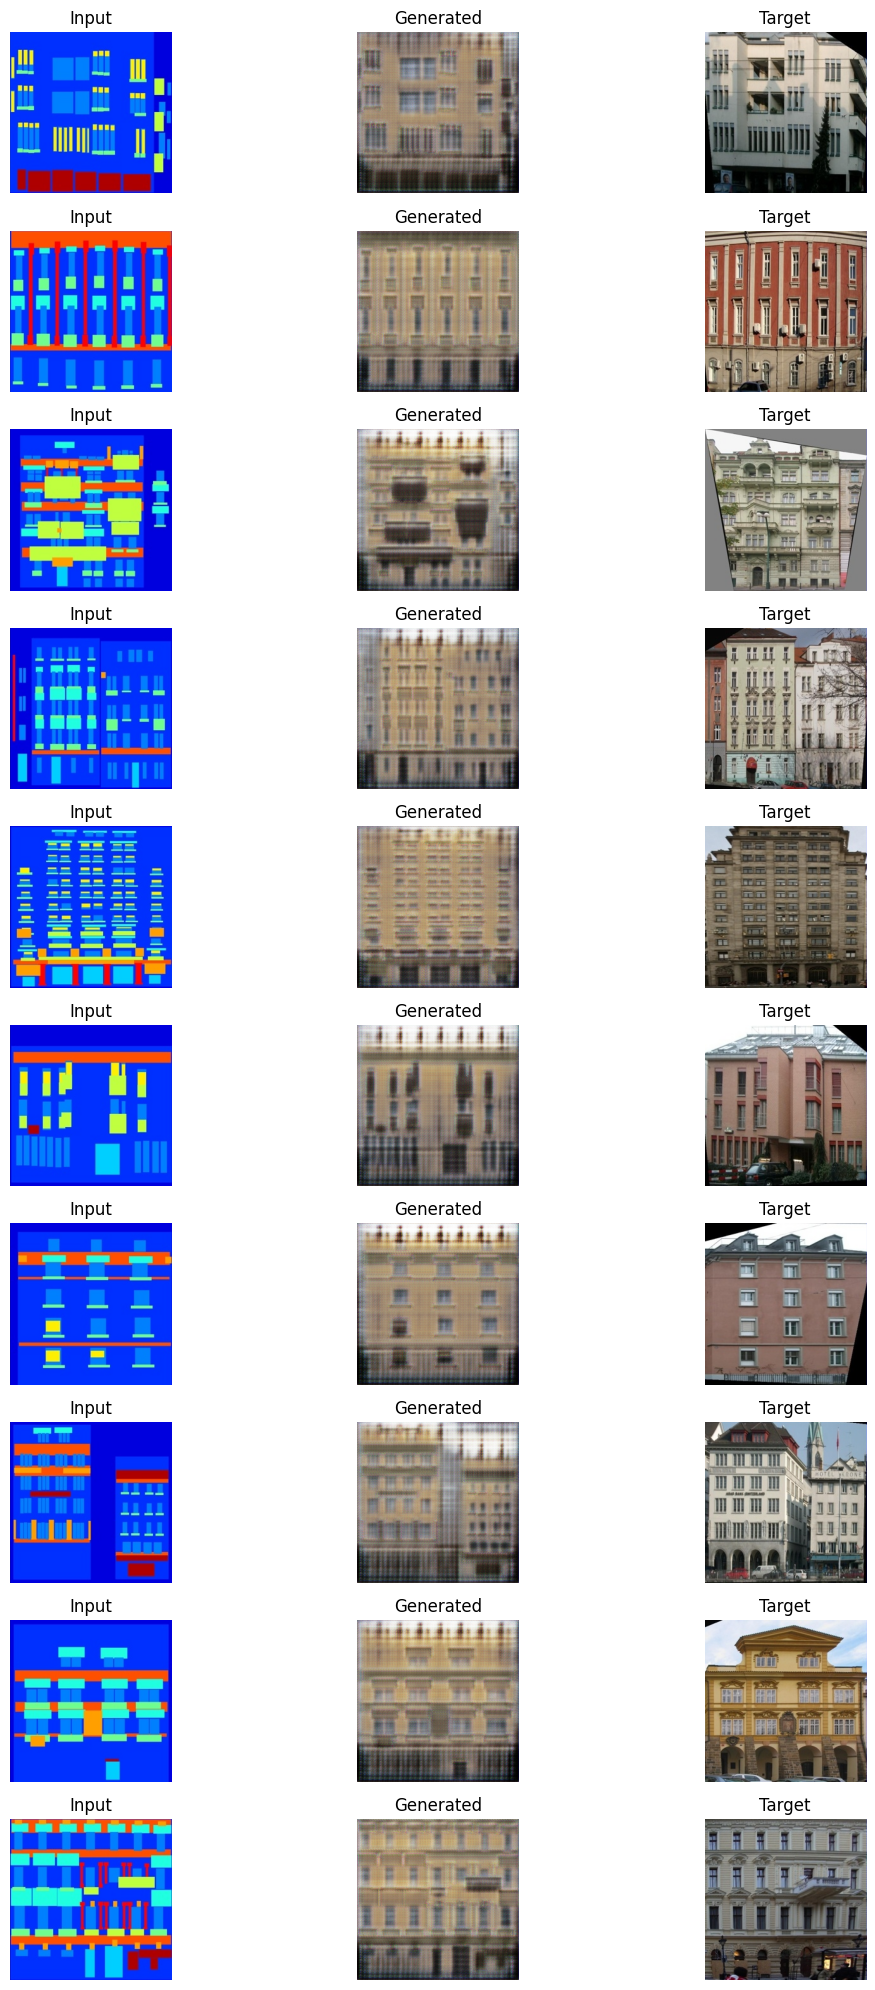

In [11]:
# Example usage after training:
visualize_samples(gen, dataset, num_samples=10)

# Increasing the number of epochs to 20


In [12]:
num_epochs = 20  # For demonstration; increase for better results.
lambda_L1 = 100

for epoch in range(num_epochs):
    for i, batch in (
        pbar := tqdm(enumerate(dataloader), total=len(dataloader), unit='batch')
    ):
        real_input = batch["input"].to(device)
        real_target = batch["target"].to(device)
        batch_size = real_input.size(0)

        # Adversarial ground truths
        valid = torch.ones((batch_size, 1, 30, 30), device=device)  # PatchGAN output shape may be ~30x30 for 256x256 inputs
        fake = torch.zeros((batch_size, 1, 30, 30), device=device)

        ## --------------------
        ## Train Generator
        ## --------------------
        optimizer_G.zero_grad()

        # Generate fake images
        fake_target = gen(real_input)

        # GAN loss (try to fool the discriminator)
        pred_fake = disc(real_input, fake_target)
        loss_GAN = criterion_GAN(pred_fake, valid)

        # L1 loss
        loss_L1 = criterion_L1(fake_target, real_target)

        # Total generator loss
        loss_G = loss_GAN + lambda_L1 * loss_L1
        loss_G.backward()
        optimizer_G.step()

        ## --------------------
        ## Train Discriminator
        ## --------------------
        optimizer_D.zero_grad()

        # Real loss
        pred_real = disc(real_input, real_target)
        loss_real = criterion_GAN(pred_real, valid)

        # Fake loss
        pred_fake = disc(real_input, fake_target.detach())
        loss_fake = criterion_GAN(pred_fake, fake)

        # Total discriminator loss
        loss_D = (loss_real + loss_fake) * 0.5
        loss_D.backward()
        optimizer_D.step()

        pbar.set_description(f'[epoch {epoch+1}/{num_epochs}] G_loss: {loss_G.item():.4f} D_loss: {loss_D.item():.4f}')

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

... (10 outputs left out)

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

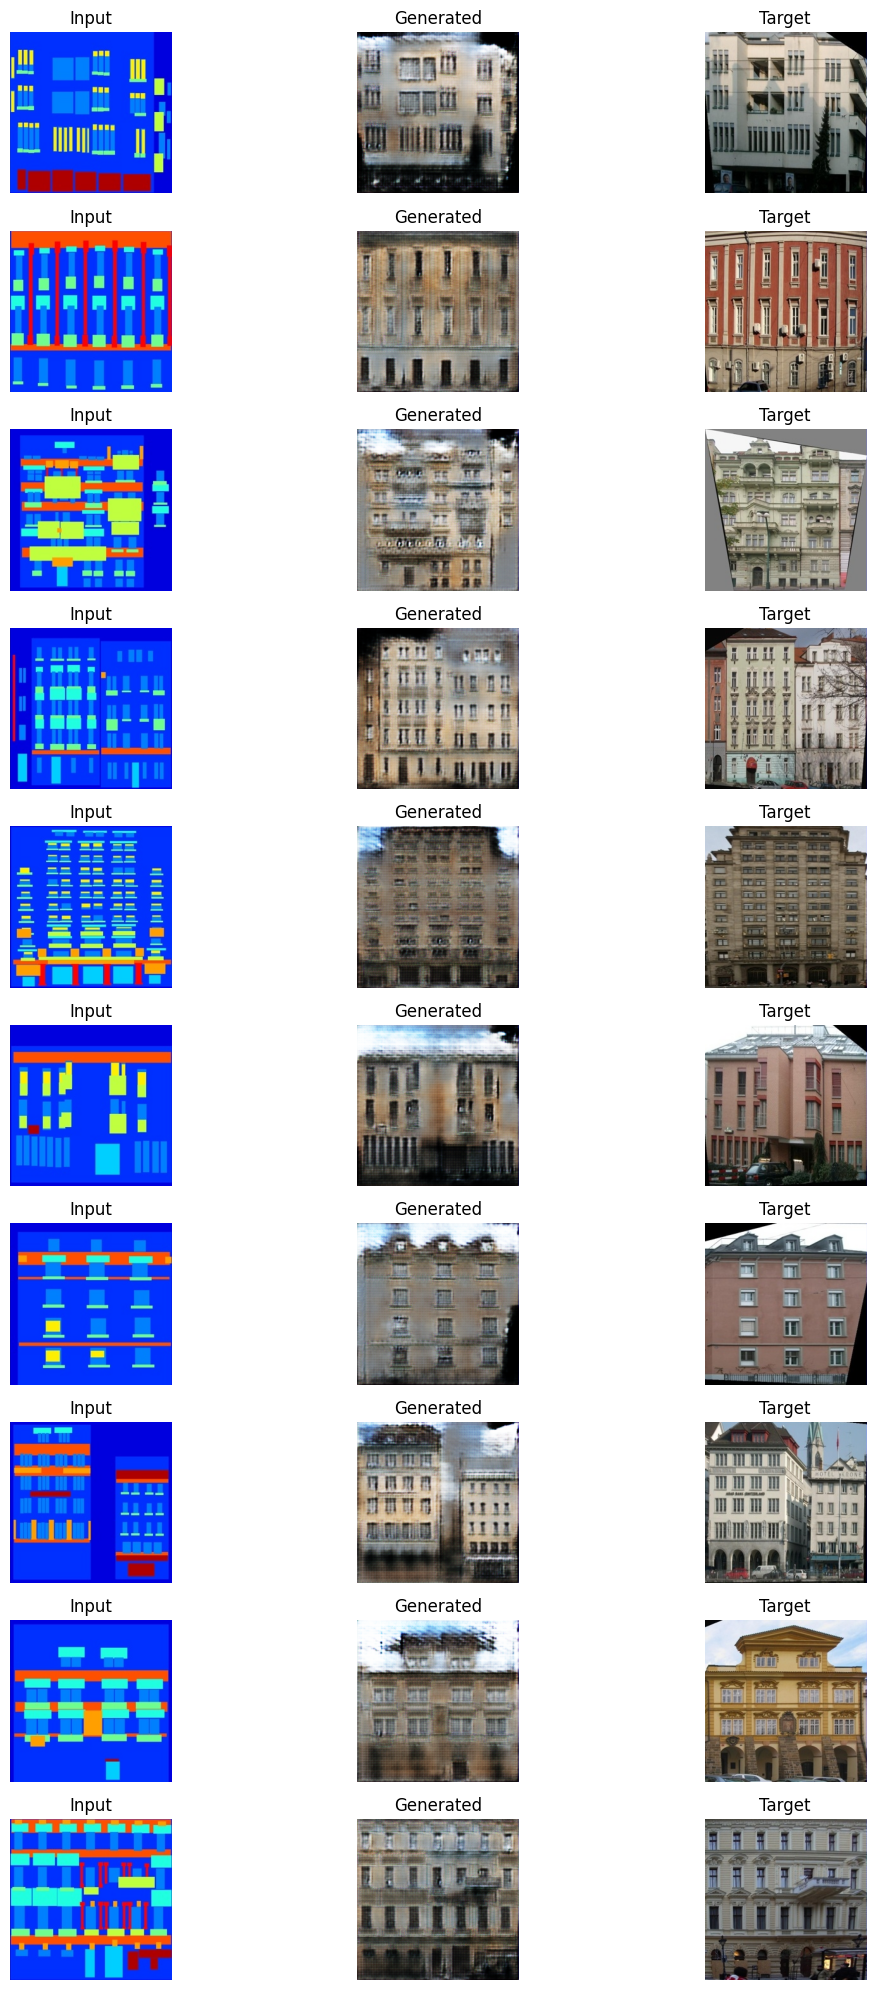

In [13]:
# Example usage after training:
visualize_samples(gen, dataset, num_samples=10)

# Increasing the number of epochs to 50


In [14]:
num_epochs = 50
lambda_L1 = 100

for epoch in range(num_epochs):
    for i, batch in (
        pbar := tqdm(enumerate(dataloader), total=len(dataloader), unit='batch')
    ):
        real_input = batch["input"].to(device)
        real_target = batch["target"].to(device)
        batch_size = real_input.size(0)

        # Adversarial ground truths
        valid = torch.ones((batch_size, 1, 30, 30), device=device)  # PatchGAN output shape may be ~30x30 for 256x256 inputs
        fake = torch.zeros((batch_size, 1, 30, 30), device=device)

        ## --------------------
        ## Train Generator
        ## --------------------
        optimizer_G.zero_grad()

        # Generate fake images
        fake_target = gen(real_input)

        # GAN loss (try to fool the discriminator)
        pred_fake = disc(real_input, fake_target)
        loss_GAN = criterion_GAN(pred_fake, valid)

        # L1 loss
        loss_L1 = criterion_L1(fake_target, real_target)

        # Total generator loss
        loss_G = loss_GAN + lambda_L1 * loss_L1
        loss_G.backward()
        optimizer_G.step()

        ## --------------------
        ## Train Discriminator
        ## --------------------
        optimizer_D.zero_grad()

        # Real loss
        pred_real = disc(real_input, real_target)
        loss_real = criterion_GAN(pred_real, valid)

        # Fake loss
        pred_fake = disc(real_input, fake_target.detach())
        loss_fake = criterion_GAN(pred_fake, fake)

        # Total discriminator loss
        loss_D = (loss_real + loss_fake) * 0.5
        loss_D.backward()
        optimizer_D.step()

        pbar.set_description(f'[epoch {epoch+1}/{num_epochs}] G_loss: {loss_G.item():.4f} D_loss: {loss_D.item():.4f}')

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

... (40 outputs left out)

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

  0%|          | 0/100 [00:00<?, ?batch/s]

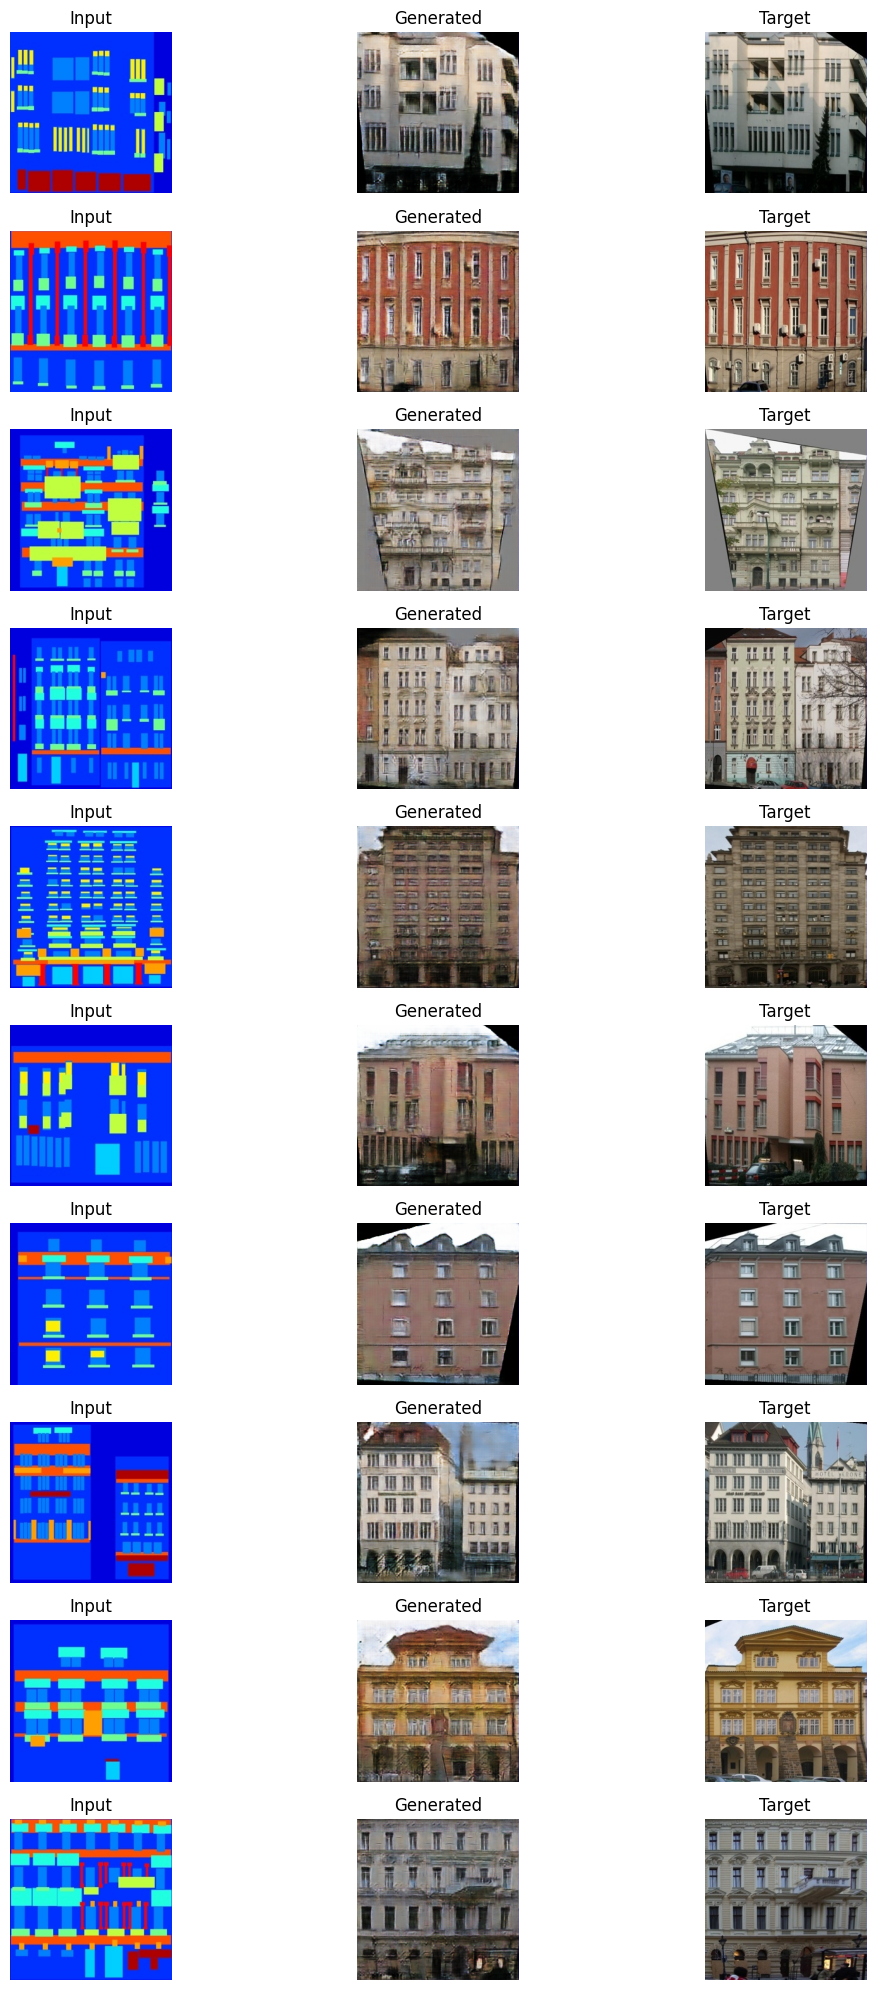

In [15]:
# Example usage after training:
visualize_samples(gen, dataset, num_samples=10)

## Evaluating on test dataset

In [16]:
# Define transforms: resize and convert to tensor (normalize to [-1, 1])
transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Resize((256, 256)),
    T.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

datasets_root = "/pgeoprj2/ciag2024/dados/pix2pix/facades/"
test_dataset = Pix2PixDataset(root_dir=datasets_root, mode="test", transform=transform, target='left')

# Create a DataLoader for the test_dataset
test_dataloader = DataLoader(test_dataset, batch_size=4, shuffle=True, num_workers=2)

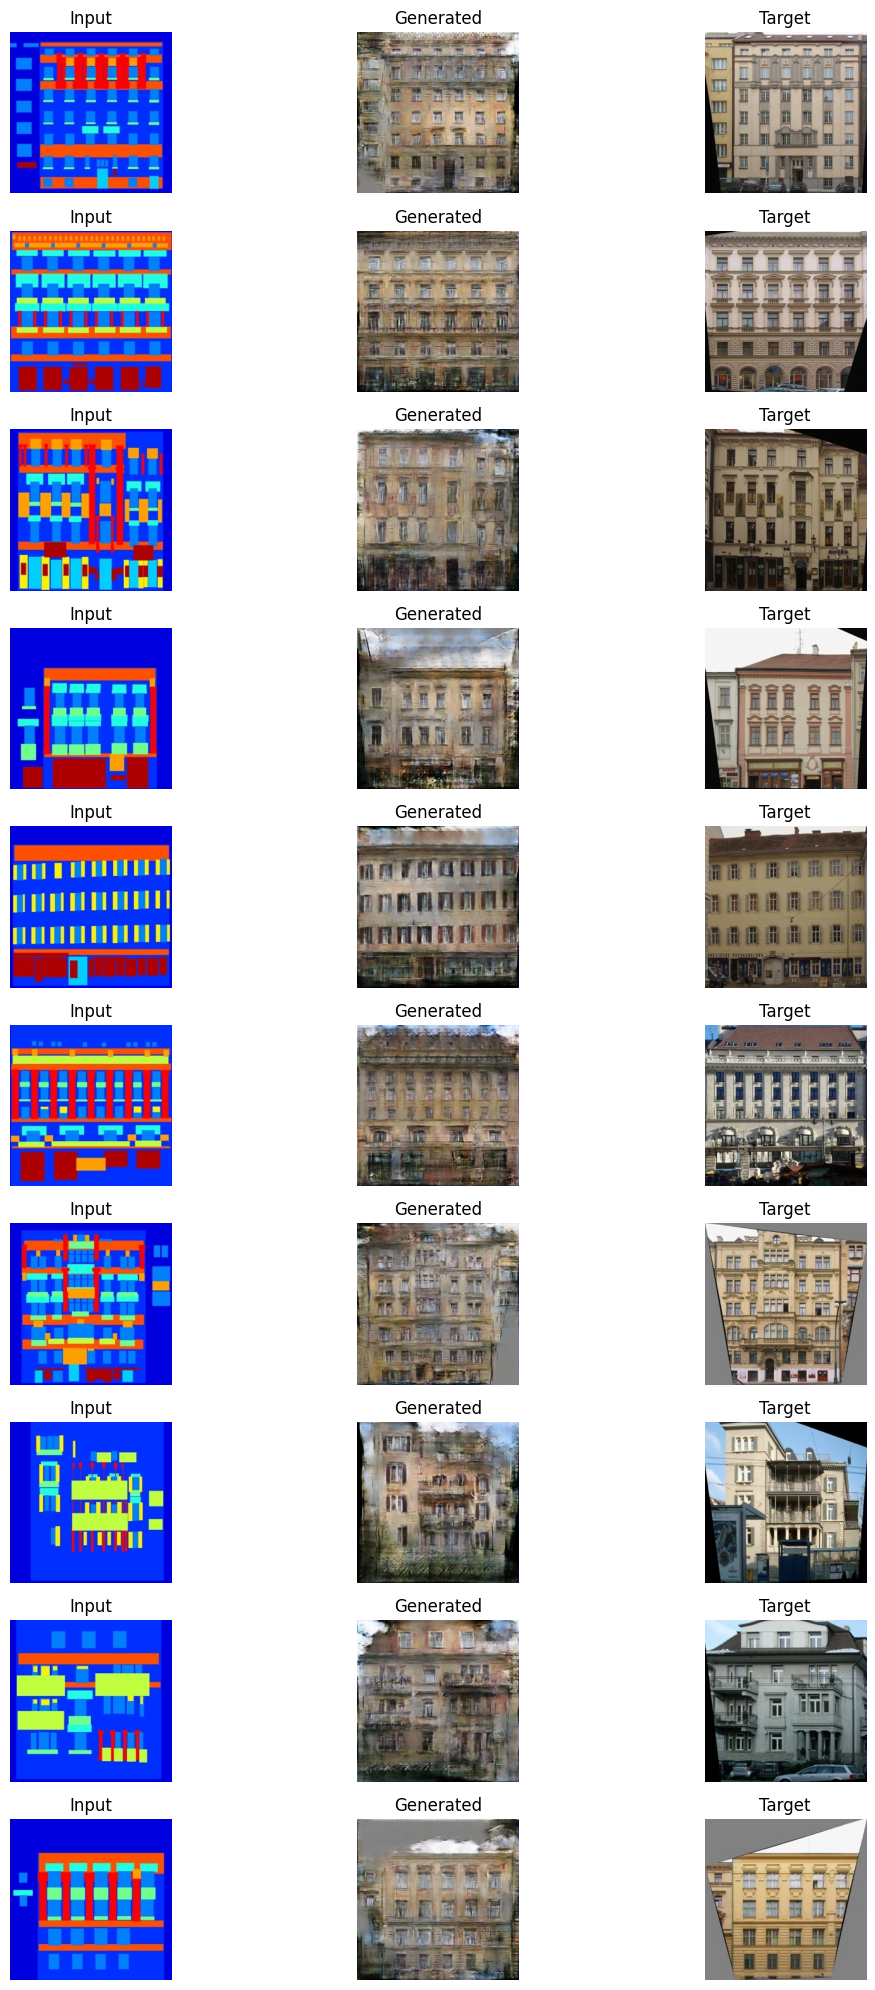

In [17]:
# Example usage after training:
visualize_samples(gen, test_dataset, num_samples=10)